In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PC = "PC2"
results = f"results/{PC}"

# Ítem A

In [23]:
df_a = pd.read_csv(f"{results}/item_a.csv")
df_a

,N,n,tiempo_ms,checksum
0,2048,2048,2430.21,172.331627
1,2048,1024,1257.26,172.331627
2,2048,512,1325.59,172.331627
3,2048,256,1556.16,172.331627
4,2048,128,1750.10,172.331627
5,2048,64,2179.41,172.331627
6,2048,32,2021.38,172.331627


Text(0, 0.5, 'Tiempo (ms)')

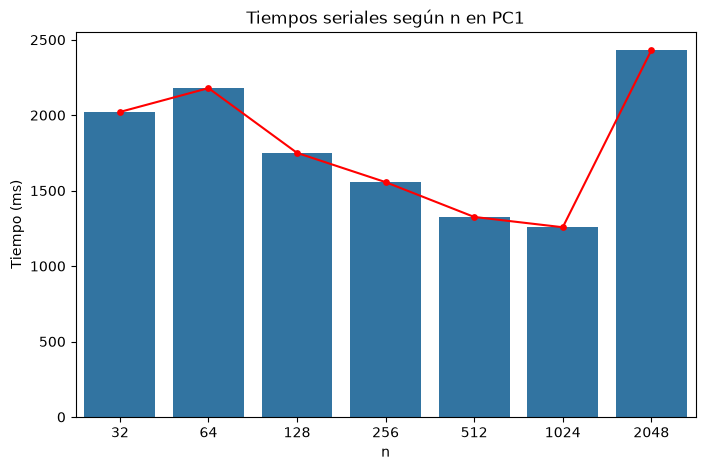

In [25]:
fig, ax = plt.subplots(figsize=(8,5))

sns.barplot(data=df_a, x="n", y="tiempo_ms", ax=ax)
sns.pointplot(data=df_a, x='n', y='tiempo_ms', ax=ax, color='red', marker='o', linewidth=1.5)

ax.set_title(f"Tiempos seriales según n en {PC}")
ax.set_ylabel("Tiempo (ms)")

# Algoritmo 1

In [32]:
df_1 = pd.read_csv(f"{results}/alg_1.csv")

t1_map = df_1[df_1['p'] == 1].set_index('N')['tiempo_ms']
df_1['T1'] = df_1['N'].map(t1_map)

df_1['Speedup'] = (df_1['T1'] / df_1['tiempo_ms']).round(2)
df_1['Eficiencia'] = (df_1['Speedup'] / df_1['p']).round(2)

df_1

,N,p,tiempo_ms,checksum,T1,Speedup,Eficiencia
0,1024,1,134.42,52.223927,134.42,1.00,1.00
1,1024,2,64.83,52.223927,134.42,2.07,1.03
2,1024,4,35.40,52.223927,134.42,3.80,0.95
3,1024,8,38.10,52.223927,134.42,3.53,0.44
4,2048,1,2381.95,172.331627,2381.95,1.00,1.00
5,2048,2,1493.18,172.331627,2381.95,1.60,0.80
6,2048,4,818.10,172.331627,2381.95,2.91,0.73
7,2048,8,428.95,172.331627,2381.95,5.55,0.69
8,4096,1,19625.36,125.903028,19625.36,1.00,1.00
9,4096,2,12572.25,125.903028,19625.36,1.56,0.78


# Algoritmo 2

In [35]:
df_2 = pd.read_csv(f"{results}/alg_2.csv")

# 2. Cálculo para Algoritmo 2 (Fijando la elección óptima n=256)
df_2_best = df_2[df_2['n'] == 256].copy()

# Mapear T(1) dinámicamente según el valor de N para n=256
t1_map_2 = df_2_best[df_2_best['p'] == 1].set_index('N')['tiempo_ms']
df_2_best['T1'] = df_2_best['N'].map(t1_map_2)

df_2_best['Speedup'] = (df_2_best['T1'] / df_2_best['tiempo_ms']).round(2)
df_2_best['Eficiencia'] = (df_2_best['Speedup'] / df_2_best['p']).round(2)

# Revisión rápida de la escalabilidad débil (ítem f) en Algoritmo 2
df_2_best

,N,n,p,tiempo_ms,checksum,T1,Speedup,Eficiencia
12,1024,256,1,190.41,52.223927,190.41,1.00,1.00
13,1024,256,2,95.00,52.223927,190.41,2.00,1.00
14,1024,256,4,54.66,52.223927,190.41,3.48,0.87
15,1024,256,8,45.66,52.223927,190.41,4.17,0.52
40,2048,256,1,1566.01,172.331627,1566.01,1.00,1.00
41,2048,256,2,783.62,172.331627,1566.01,2.00,1.00
42,2048,256,4,441.99,172.331627,1566.01,3.54,0.88
43,2048,256,8,318.09,172.331627,1566.01,4.92,0.62
68,4096,256,1,13254.97,125.903028,13254.97,1.00,1.00
69,4096,256,2,6497.50,125.903028,13254.97,2.04,1.02


# Algoritmo 3

In [33]:
df_3 = pd.read_csv(f"{results}/alg_3.csv")

t1_map = df_3[df_3['p'] == 1].set_index('N')['tiempo_ms']
df_3['T1'] = df_3['N'].map(t1_map)

df_3['Speedup'] = (df_3['T1'] / df_3['tiempo_ms']).round(2)
df_3['Eficiencia'] = (df_3['Speedup'] / df_3['p']).round(2)

df_3

,N,p,tiempo_ms,checksum,T1,Speedup,Eficiencia
0,1024,1,98.12,52.223927,98.12,1.00,1.00
1,1024,2,53.18,52.223927,98.12,1.85,0.92
2,1024,4,36.56,52.223927,98.12,2.68,0.67
3,1024,8,29.28,52.223927,98.12,3.35,0.42
4,2048,1,2165.25,172.331627,2165.25,1.00,1.00
5,2048,2,1424.44,172.331627,2165.25,1.52,0.76
6,2048,4,740.52,172.331627,2165.25,2.92,0.73
7,2048,8,403.21,172.331627,2165.25,5.37,0.67
8,4096,1,18875.74,125.903028,18875.74,1.00,1.00
9,4096,2,12125.29,125.903028,18875.74,1.56,0.78


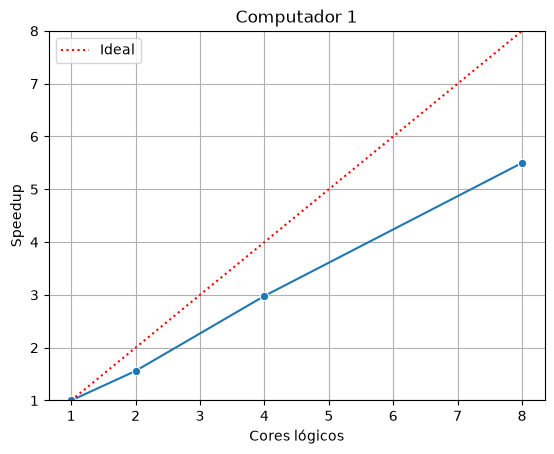

In [ ]:
fig, ax = plt.subplots()

sns.lineplot(data=df_3, x="p", y="speedup", marker="o", ax=ax)
ax.axline((1, 1), slope=1, color='red', linestyle=':', label='Ideal')
ax.set_ylim(1,8)
ax.set_title("Computador 1")
ax.set_ylabel("Speedup")
ax.set_xlabel("Cores lógicos")
ax.grid(True)
ax.legend()

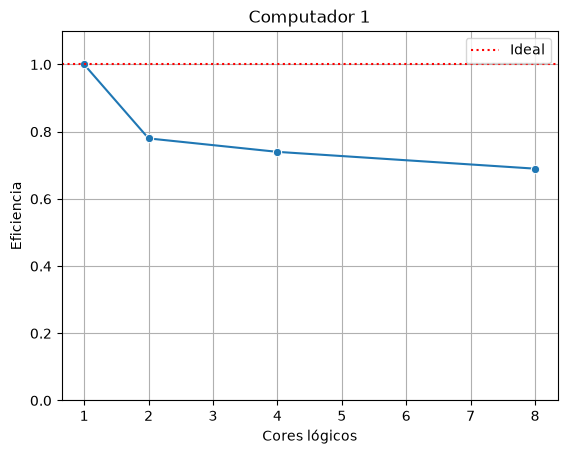

In [ ]:
fig, ax = plt.subplots()

sns.lineplot(data=df_3, x="p", y="eficiencia", marker="o", ax=ax)
ax.axline((1, 1), slope=0, color='red', linestyle=':', label='Ideal')
ax.set_ylim(0,1.1)
ax.set_title("Computador 1")
ax.set_ylabel("Eficiencia")
ax.set_xlabel("Cores lógicos")
ax.grid(True)
ax.legend()